Video loaded successfully. FPS: 30.00
Reference frame set at index 20 (Time: 0.67s).
Starting frame-by-frame comparison...
Frame 21: FPS: 30.00 / Processing time: 0.002220s
Frame 22: FPS: 30.00 / Processing time: 0.000963s
Frame 23: FPS: 30.00 / Processing time: 0.000860s
Frame 24: FPS: 30.00 / Processing time: 0.000941s
Frame 25: FPS: 30.00 / Processing time: 0.000937s
Frame 26: FPS: 30.00 / Processing time: 0.000997s
Frame 27: FPS: 30.00 / Processing time: 0.003263s
Frame 28: FPS: 30.00 / Processing time: 0.001026s
Frame 29: FPS: 30.00 / Processing time: 0.000930s
Frame 30: FPS: 30.00 / Processing time: 0.000991s
Frame 31: FPS: 30.00 / Processing time: 0.000935s
Frame 32: FPS: 30.00 / Processing time: 0.000914s
Frame 33: FPS: 30.00 / Processing time: 0.001142s
Frame 34: FPS: 30.00 / Processing time: 0.002323s
Frame 35: FPS: 30.00 / Processing time: 0.001002s
Frame 36: FPS: 30.00 / Processing time: 0.000966s
Frame 37: FPS: 30.00 / Processing time: 0.002093s
Frame 38: FPS: 30.00 / Proc

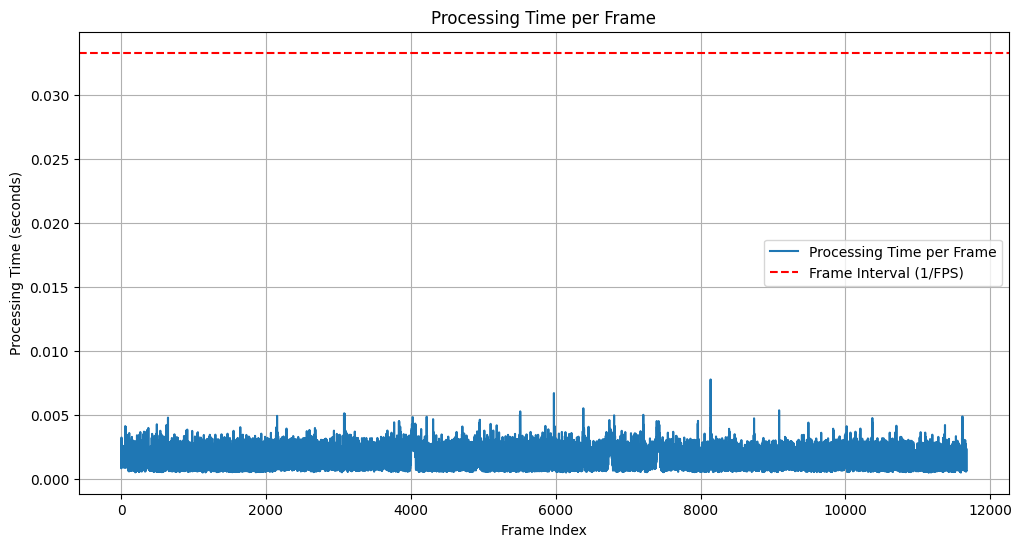

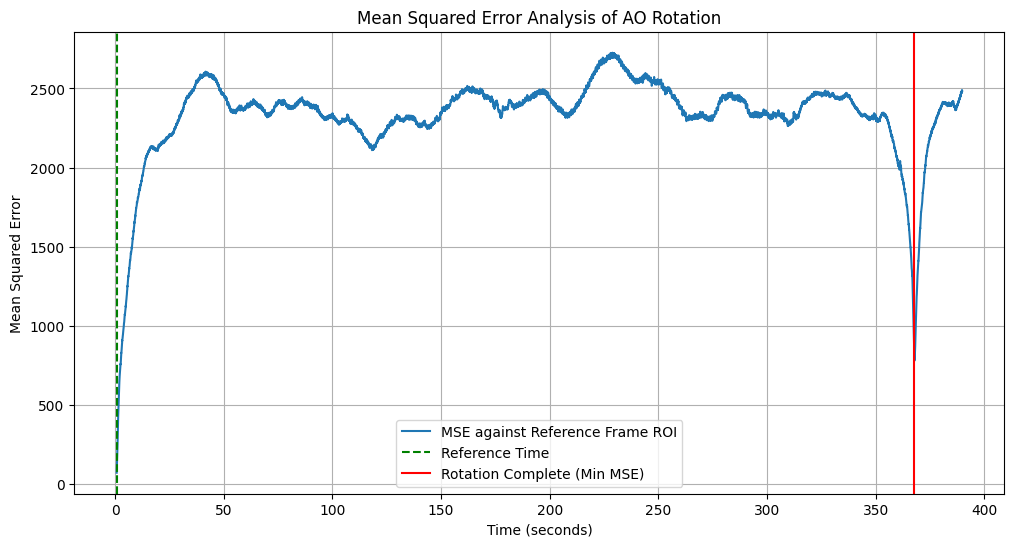

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

""" Fast Rotation Cycle Estimation that outputs the rotation cyle estimate as well as showing the runtime of this approach over time"""

VIDEO_PATH = "AO_Rotation_Recording_full3.mp4" 
REFERENCE_FRAME_INDEX = 20 
ROI_SCALE = 0.50 

def calculate_mse(imageA, imageB):
    """
    Calculates the Mean Squared Error (MSE) between two image arrays.
    """
    err = np.sum((imageA.astype("float") - imageB.astype("float")) ** 2)
    err /= float(imageA.shape[0] * imageA.shape[1])
    return err

def get_roi_frame(frame, scale):
    """
    Crops the central area of the frame based on the scale factor.
    """

    h, w, _ = frame.shape

    roi_w = int(w * scale)
    roi_h = int(h * scale)

    start_x = (w - roi_w) // 2
    start_y = (h - roi_h) // 2

    # Crop the central region
    roi = frame[start_y:start_y + roi_h, start_x:start_x + roi_w]
    gray_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    return gray_roi

def analyze_rotation(video_path, ref_index, scale):
    """
    Loads video, computes MSE of the central ROI against a reference frame,
    and finds the minimum MSE to estimate the rotation period.
    """

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)

    # Read frames until the reference index is reached
    for i in range(ref_index):
        ret, frame = cap.read()

    ref_frame = frame
    ref_time_sec = ref_index / fps

    # Get the Region of Interest for the reference frame
    reference_roi = get_roi_frame(ref_frame, scale)

    print(f"Reference frame set at index {ref_index} (Time: {ref_time_sec:.2f}s).")

    # Store results: (time_in_seconds, mse_value)
    results = []
    processing_times = []

    min_mse = float('inf')
    best_match_frame_index = -1
    best_match_time_sec = -1.0
    current_frame_index = ref_index

    print("Starting frame-by-frame comparison...")

    while cap.isOpened():
        ret, current_frame = cap.read()

        if not ret:
            break

        current_frame_index += 1
        current_time_sec = current_frame_index / fps

        # Start timing for the processing of this frame
        frame_start_time = time.time()

        # process current frame
        current_roi = get_roi_frame(current_frame, scale)
        mse = calculate_mse(reference_roi, current_roi)
        results.append((current_time_sec, mse))

        # Measure processing time for this frame
        frame_end_time = time.time()
        processing_time = frame_end_time - frame_start_time
        processing_times.append(processing_time)

        # find the best MSE match
        if current_time_sec > ref_time_sec + 5.0: 
            if mse < min_mse:
                min_mse = mse
                best_match_frame_index = current_frame_index
                best_match_time_sec = current_time_sec

    cap.release()
    cv2.destroyAllWindows()

    rotation_cycle_time = best_match_time_sec - ref_time_sec

    print("\n--- Results ---")
    print(f"Reference Frame Time: {ref_time_sec:.2f} seconds")
    print(f"Best Match Frame Index: {best_match_frame_index}")
    print(f"Best Match Time: {best_match_time_sec:.2f} seconds (Minimum MSE: {min_mse:.2f})")
    print(f"Estimated Single Rotation Cycle: {rotation_cycle_time:.2f} seconds")

    # Plot processing times
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(processing_times)), processing_times, label='Processing Time per Frame')
    plt.axhline(1/fps, color='red', linestyle='--', label='Frame Interval (1/FPS)')
    plt.title('Processing Time per Frame')
    plt.xlabel('Frame Index')
    plt.ylabel('Processing Time (seconds)')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Plot MSE results
    times, mses = zip(*results)
    plt.figure(figsize=(12, 6))
    plt.plot(times, mses, label='MSE against Reference Frame ROI')
    plt.axvline(ref_time_sec, color='green', linestyle='--', label='Reference Time')
    plt.axvline(best_match_time_sec, color='red', linestyle='-', label='Rotation Complete (Min MSE)')
    plt.title('Mean Squared Error Analysis of AO Rotation')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Mean Squared Error')
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    analyze_rotation(VIDEO_PATH, REFERENCE_FRAME_INDEX, ROI_SCALE)
